<a href="https://colab.research.google.com/github/Rohan-1103/Pilot_Employee_Churn_Prediction/blob/main/Pilot_Analysis_Employee_Churn.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Connect to Big Query

In [1]:
# libraries that we need
from google.cloud import bigquery
from google.colab import auth

# authenticate
auth.authenticate_user()

# initilize the client for big query
project_id = 'pilot-churn-prediction'
client = bigquery.Client(project = project_id, location = 'US')

# Get the dataset and table

In [2]:
# connect to dataset
dataset_ref = client.dataset('employeedata', project = project_id)
dataset = client.get_dataset(dataset_ref)

# get tables
table_ref = dataset.table('tbl_hr_data')
table = client.get_table(table_ref)

new_table_ref = dataset.table('tbl_new_employees')
new_table = client.get_table(new_table_ref)

In [3]:
table.schema

[SchemaField('satisfaction_level', 'FLOAT', 'NULLABLE', None, None, (), None, None),
 SchemaField('last_evaluation', 'FLOAT', 'NULLABLE', None, None, (), None, None),
 SchemaField('number_project', 'INTEGER', 'NULLABLE', None, None, (), None, None),
 SchemaField('average_montly_hours', 'INTEGER', 'NULLABLE', None, None, (), None, None),
 SchemaField('time_spend_company', 'INTEGER', 'NULLABLE', None, None, (), None, None),
 SchemaField('Work_accident', 'INTEGER', 'NULLABLE', None, None, (), None, None),
 SchemaField('Quit_the_Company', 'INTEGER', 'NULLABLE', None, None, (), None, None),
 SchemaField('promotion_last_5years', 'INTEGER', 'NULLABLE', None, None, (), None, None),
 SchemaField('Departments', 'STRING', 'NULLABLE', None, None, (), None, None),
 SchemaField('salary', 'STRING', 'NULLABLE', None, None, (), None, None),
 SchemaField('employee_id', 'STRING', 'NULLABLE', None, None, (), None, None)]

In [4]:
new_table.schema

[SchemaField('satisfaction_level', 'FLOAT', 'NULLABLE', None, None, (), None, None),
 SchemaField('last_evaluation', 'FLOAT', 'NULLABLE', None, None, (), None, None),
 SchemaField('number_project', 'INTEGER', 'NULLABLE', None, None, (), None, None),
 SchemaField('average_montly_hours', 'INTEGER', 'NULLABLE', None, None, (), None, None),
 SchemaField('time_spend_company', 'INTEGER', 'NULLABLE', None, None, (), None, None),
 SchemaField('Work_accident', 'INTEGER', 'NULLABLE', None, None, (), None, None),
 SchemaField('Quit_the_Company', 'INTEGER', 'NULLABLE', None, None, (), None, None),
 SchemaField('promotion_last_5years', 'INTEGER', 'NULLABLE', None, None, (), None, None),
 SchemaField('Departments', 'STRING', 'NULLABLE', None, None, (), None, None),
 SchemaField('salary', 'STRING', 'NULLABLE', None, None, (), None, None),
 SchemaField('employee_id', 'STRING', 'NULLABLE', None, None, (), None, None)]

# Convert to dataframe

In [5]:
df = client.list_rows(table = table).to_dataframe()
df.head()

df2 = client.list_rows(table = new_table).to_dataframe()
df2.head()

,satisfaction_level,last_evaluation,number_project,average_montly_hours,time_spend_company,Work_accident,Quit_the_Company,promotion_last_5years,Departments,salary,employee_id
0,0.537849,0.122914,2,208,2,0,0,0,IT,high,NE15043
1,0.056211,0.322600,2,229,5,1,0,0,IT,low,NE15086
2,0.555186,0.555949,2,187,3,0,0,0,RandD,medium,NE15035
3,0.605273,0.713086,2,218,3,0,0,0,RandD,high,NE15069
4,0.043437,0.162372,2,175,3,0,0,0,RandD,high,NE15082


# Build Model

## Install pycaret

In [6]:
# !pip install --pre pycaret

In [7]:
!pip install autogluon.tabular

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 514.8/514.8 kB 20.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 248.4/248.4 kB 26.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 112.3/112.3 kB 13.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 90.7/90.7 kB 10.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 140.0/140.0 kB 15.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 16.1/16.1 MB 101.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 90.2/90.2 kB 10.1 MB/s eta 0:00:00


## Code and Train model

In [9]:
# get our model
# from pycaret.classification import *

In [10]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 15004 entries, 0 to 15003
Data columns (total 11 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   satisfaction_level     15004 non-null  float64
 1   last_evaluation        15004 non-null  float64
 2   number_project         14999 non-null  Int64  
 3   average_montly_hours   15004 non-null  Int64  
 4   time_spend_company     14999 non-null  Int64  
 5   Work_accident          15000 non-null  Int64  
 6   Quit_the_Company       15004 non-null  Int64  
 7   promotion_last_5years  15004 non-null  Int64  
 8   Departments            15004 non-null  object 
 9   salary                 15004 non-null  object 
 10  employee_id            15004 non-null  object 
dtypes: Int64(6), float64(2), object(3)
memory usage: 1.3+ MB


In [11]:
from autogluon.tabular import TabularPredictor

# Prepare the training dataset by dropping the non-predictive 'employee_id' column
train_data = df.drop(columns=['employee_id'])

# Initialize and fit the predictor
label = 'Quit_the_Company'
predictor = TabularPredictor(label=label).fit(train_data)

No path specified. Models will be saved in: "AutogluonModels/ag-20261013_163454"
Verbosity: 2 (Standard Logging)
=================== System Info ===================
AutoGluon Version:  1.6.3
Python Version:     3.13.15
Operating System:   Linux
Platform Machine:   x86_64
Platform Version:   #1 SMP Thu Apr 30 18:17:14 UTC 2026
CPU Count:          2
Pytorch Version:    2.11.0+cu130
CUDA Version:       13.0
GPU Memory:         GPU 0: 14.56/14.56 GB
Total GPU Memory:   Free: 14.56 GB, Allocated: 0.00 GB, Total: 14.56 GB
GPU Count:          1
Memory Avail:       10.69 GB / 12.67 GB (84.4%)
Disk Space Avail:   70.20 GB / 112.64 GB (62.3%)
No presets specified! To achieve strong results with AutoGluon, it is recommended to use the available presets. Defaulting to `'medium'`...
	Recommended Presets (For more details refer to https://auto.gluon.ai/stable/tutorials/tabular/tabular-essentials.html#presets):
	presets='extreme'  : Use this if you have a GPU. The go-to preset for best results, and t

[1000]	valid_set's binary_error: 0.0579614
[2000]	valid_set's binary_error: 0.0526316


	0.9507	 = Validation score   (accuracy)
	5.26s	 = Training   runtime
	0.35s	 = Validation runtime
Fitting model: RandomForestGini ...
	Fitting with cpus=2, gpus=0, mem=0.1/10.4 GB
	0.944	 = Validation score   (accuracy)
	2.78s	 = Training   runtime
	0.1s	 = Validation runtime
Fitting model: RandomForestEntr ...
	Fitting with cpus=2, gpus=0, mem=0.1/10.4 GB
	0.9434	 = Validation score   (accuracy)
	2.71s	 = Training   runtime
	0.11s	 = Validation runtime
Fitting model: CatBoost ...
	Fitting with cpus=1, gpus=0
		`import catboost` failed. A quick tip is to install via `pip install autogluon.tabular[catboost]==1.6.3`.
Fitting model: ExtraTreesGini ...
	Fitting with cpus=2, gpus=0, mem=0.1/10.3 GB
	0.946	 = Validation score   (accuracy)
	2.02s	 = Training   runtime
	0.12s	 = Validation runtime
Fitting model: ExtraTreesEntr ...
	Fitting with cpus=2, gpus=0, mem=0.1/10.3 GB
	0.946	 = Validation score   (accuracy)
	2.06s	 = Training   runtime
	0.14s	 = Validation runtime
Fitting model: Neura

In [12]:
# Show the training leaderboard of all models
leaderboard = predictor.leaderboard(silent=False)
print(leaderboard)

# Prepare new employee dataset (drop employee_id and target label if present for predictions)
test_data = df2.drop(columns=['employee_id', 'Quit_the_Company'], errors='ignore')

# Make predictions
predictions = predictor.predict(test_data)
df2['predicted_churn'] = predictions

# Display a summary of the predictions
print("\nPredicted Churn Count:")
print(df2['predicted_churn'].value_counts())

# Display some of the predicted results
df2[['employee_id', 'predicted_churn']].head(10)

                  model  score_val eval_metric  pred_time_val    fit_time  pred_time_val_marginal  fit_time_marginal  stack_level  can_infer  fit_order
0              LightGBM   0.950700    accuracy       0.349351    5.256549                0.349351           5.256549            1       True          2
1   WeightedEnsemble_L2   0.950700    accuracy       0.350647    5.432235                0.001296           0.175686            2       True         11
2         LightGBMLarge   0.947368    accuracy       0.247559    2.777591                0.247559           2.777591            1       True         10
3        ExtraTreesGini   0.946036    accuracy       0.120657    2.023183                0.120657           2.023183            1       True          5
4        ExtraTreesEntr   0.946036    accuracy       0.142492    2.062397                0.142492           2.062397            1       True          6
5      RandomForestGini   0.944037    accuracy       0.099191    2.781118               

,employee_id,predicted_churn
0,NE15043,0
1,NE15086,1
2,NE15035,0
3,NE15069,0
4,NE15082,1
5,NE15092,0
6,NE15097,0
7,NE15102,0
8,NE15029,0
9,NE15040,0


In [13]:
import pandas as pd
from sklearn.metrics import classification_report, roc_auc_score

# 1. Split the training data to retrieve the validation set AutoGluon used internally
# Or, we can simply evaluate on the entire training set (or a holdout) to get metrics.
# Let's generate predictions on our training set from the XGBoost model to inspect detailed metrics.

# Get predictions and probabilities specifically from the XGBoost model
xgb_preds = predictor.predict(train_data, model='XGBoost')
xgb_probs = predictor.predict_proba(train_data, model='XGBoost')[1.0]

y_true = train_data['Quit_the_Company'].astype(int)

# Calculate metrics using scikit-learn
print("=== XGBoost Model Performance Report (on Training Data) ===")
print(classification_report(y_true, xgb_preds.astype(int), digits=4))

roc_auc = roc_auc_score(y_true, xgb_probs)
print(f"ROC AUC Score: {roc_auc:.4f}")

=== XGBoost Model Performance Report (on Training Data) ===
              precision    recall  f1-score   support

           0     0.9570    0.9815    0.9691     11428
           1     0.9357    0.8591    0.8958      3576

    accuracy                         0.9523     15004
   macro avg     0.9464    0.9203    0.9324     15004
weighted avg     0.9519    0.9523    0.9516     15004

ROC AUC Score: 0.9880


In [14]:
# 2. Use the specific XGBoost model to generate predictions for the new employees (df2)
test_data = df2.drop(columns=['employee_id', 'Quit_the_Company', 'predicted_churn'], errors='ignore')

# Predict using only the XGBoost model
df2['xgb_predicted_churn'] = predictor.predict(test_data, model='XGBoost')

print("=== Churn Predictions on New Employees using XGBoost ===")
print(df2['xgb_predicted_churn'].value_counts())

# Preview predictions
df2[['employee_id', 'xgb_predicted_churn']].head(10)

=== Churn Predictions on New Employees using XGBoost ===
xgb_predicted_churn
0    88
1    12
Name: count, dtype: Int64


,employee_id,xgb_predicted_churn
0,NE15043,0
1,NE15086,1
2,NE15035,0
3,NE15069,0
4,NE15082,1
5,NE15092,0
6,NE15097,0
7,NE15102,0
8,NE15029,0
9,NE15040,0


In [15]:
# Predict using the Random Forest model (RandomForestEntr) trained by AutoGluon
final_df = df2.copy()
final_df['rf_predicted_churn'] = predictor.predict(test_data, model='RandomForestEntr')

# Display the first 5 rows of the final dataframe with employee_id and the prediction
display(final_df.head(5))

,satisfaction_level,last_evaluation,number_project,average_montly_hours,time_spend_company,Work_accident,Quit_the_Company,promotion_last_5years,Departments,salary,employee_id,predicted_churn,xgb_predicted_churn,rf_predicted_churn
0,0.537849,0.122914,2,208,2,0,0,0,IT,high,NE15043,0,0,0
1,0.056211,0.322600,2,229,5,1,0,0,IT,low,NE15086,1,1,0
2,0.555186,0.555949,2,187,3,0,0,0,RandD,medium,NE15035,0,0,0
3,0.605273,0.713086,2,218,3,0,0,0,RandD,high,NE15069,0,0,0
4,0.043437,0.162372,2,175,3,0,0,0,RandD,high,NE15082,1,1,0


In [16]:
# Create a clean final_df retaining original columns and only the XGBoost prediction
final_df = df2.copy()

# Remove any unwanted prediction columns if they exist in df2
final_df = final_df.drop(columns=['predicted_churn', 'rf_predicted_churn', 'xgb_predicted_churn'], errors='ignore')

# Generate and assign the final prediction using only XGBoost
final_df['predicted_churn'] = predictor.predict(test_data, model='XGBoost')

# Display the top 5 rows
display(final_df.head(5))

,satisfaction_level,last_evaluation,number_project,average_montly_hours,time_spend_company,Work_accident,Quit_the_Company,promotion_last_5years,Departments,salary,employee_id,predicted_churn
0,0.537849,0.122914,2,208,2,0,0,0,IT,high,NE15043,0
1,0.056211,0.322600,2,229,5,1,0,0,IT,low,NE15086,1
2,0.555186,0.555949,2,187,3,0,0,0,RandD,medium,NE15035,0
3,0.605273,0.713086,2,218,3,0,0,0,RandD,high,NE15069,0
4,0.043437,0.162372,2,175,3,0,0,0,RandD,high,NE15082,1


In [17]:
final_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100 entries, 0 to 99
Data columns (total 12 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   satisfaction_level     100 non-null    float64
 1   last_evaluation        100 non-null    float64
 2   number_project         100 non-null    Int64  
 3   average_montly_hours   100 non-null    Int64  
 4   time_spend_company     100 non-null    Int64  
 5   Work_accident          100 non-null    Int64  
 6   Quit_the_Company       100 non-null    Int64  
 7   promotion_last_5years  100 non-null    Int64  
 8   Departments            100 non-null    object 
 9   salary                 100 non-null    object 
 10  employee_id            100 non-null    object 
 11  predicted_churn        100 non-null    Int64  
dtypes: Int64(7), float64(2), object(3)
memory usage: 10.2+ KB


In [18]:
# Explicitly generate predictions on df2 using only the XGBoost model from AutoGluon
test_data = df2.drop(columns=['employee_id', 'Quit_the_Company', 'predicted_churn', 'xgb_predicted_churn', 'rf_predicted_churn'], errors='ignore')

# Create our new_predictions dataframe based on the new employees
new_predictions = df2.copy()
new_predictions = new_predictions.drop(columns=['predicted_churn', 'rf_predicted_churn', 'xgb_predicted_churn'], errors='ignore')

# Populate predictions using only the XGBoost model
new_predictions['predicted_churn'] = predictor.predict(test_data, model='XGBoost')

# Display the top 5 rows
display(new_predictions.head(5))

,satisfaction_level,last_evaluation,number_project,average_montly_hours,time_spend_company,Work_accident,Quit_the_Company,promotion_last_5years,Departments,salary,employee_id,predicted_churn
0,0.537849,0.122914,2,208,2,0,0,0,IT,high,NE15043,0
1,0.056211,0.322600,2,229,5,1,0,0,IT,low,NE15086,1
2,0.555186,0.555949,2,187,3,0,0,0,RandD,medium,NE15035,0
3,0.605273,0.713086,2,218,3,0,0,0,RandD,high,NE15069,0
4,0.043437,0.162372,2,175,3,0,0,0,RandD,high,NE15082,1


=== XGBoost Performance Metrics on New Employee Dataset ===
              precision    recall  f1-score   support

           0     1.0000    0.8800    0.9362       100
           1     0.0000    0.0000    0.0000         0

    accuracy                         0.8800       100
   macro avg     0.5000    0.4400    0.4681       100
weighted avg     1.0000    0.8800    0.9362       100



/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Recall is ill-defined and being set to 0.0 in labels with no true samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Recall is ill-defined and being set to 0.0 in labels with no true samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Recall is ill-defined and being set to 0.0 in labels with no true samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


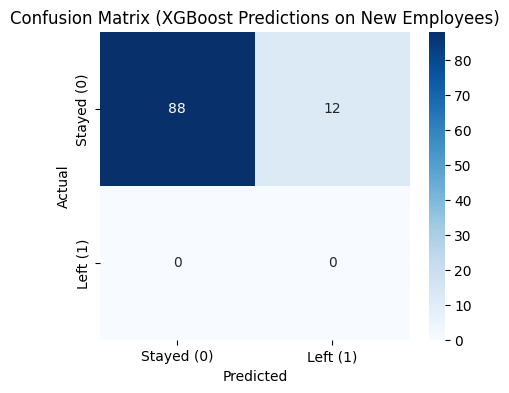

In [19]:
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

# Retrieve ground truth and predictions for df2
y_test_true = new_predictions['Quit_the_Company'].astype(int)
y_test_pred = new_predictions['predicted_churn'].astype(int)

print("=== XGBoost Performance Metrics on New Employee Dataset ===")
print(classification_report(y_test_true, y_test_pred, digits=4))

# Plot confusion matrix
cm = confusion_matrix(y_test_true, y_test_pred)
plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Stayed (0)', 'Left (1)'],
            yticklabels=['Stayed (0)', 'Left (1)'])
plt.ylabel('Actual')
plt.xlabel('Predicted')
plt.title('Confusion Matrix (XGBoost Predictions on New Employees)')
plt.show()

In [20]:
new_predictions.head()

,satisfaction_level,last_evaluation,number_project,average_montly_hours,time_spend_company,Work_accident,Quit_the_Company,promotion_last_5years,Departments,salary,employee_id,predicted_churn
0,0.537849,0.122914,2,208,2,0,0,0,IT,high,NE15043,0
1,0.056211,0.322600,2,229,5,1,0,0,IT,low,NE15086,1
2,0.555186,0.555949,2,187,3,0,0,0,RandD,medium,NE15035,0
3,0.605273,0.713086,2,218,3,0,0,0,RandD,high,NE15069,0
4,0.043437,0.162372,2,175,3,0,0,0,RandD,high,NE15082,1


In [21]:
# 1. Get prediction probabilities for all classes using the XGBoost model
xgb_probs_all = predictor.predict_proba(test_data, model='XGBoost')

# 2. Extract the probability of the predicted class (0.0 or 1.0) for each row
# xgb_probs_all is a DataFrame where columns are the class labels (0.0 and 1.0)
predicted_classes = new_predictions['predicted_churn']
prediction_scores = []

for idx, pred_class in enumerate(predicted_classes):
    # Extract probability associated with the predicted class
    score = xgb_probs_all.iloc[idx][pred_class]
    prediction_scores.append(score)

# 3. Add the prediction score column to the DataFrame
new_predictions['prediction_score'] = prediction_scores

# Display the top 5 rows with the prediction and its corresponding confidence score
display(new_predictions[['employee_id', 'predicted_churn', 'prediction_score']].head(5))

,employee_id,predicted_churn,prediction_score
0,NE15043,0,0.998722
1,NE15086,1,0.964354
2,NE15035,0,0.993932
3,NE15069,0,0.998685
4,NE15082,1,0.980842


# Write back to big query

In [22]:
new_predictions.to_gbq('employeedata.pilot_predictions',project_id, chunksize = None, if_exists='replace')

/tmp/ipykernel_3754/1923188106.py:1: FutureWarning: Starting with pandas version 3.0 all arguments of to_gbq except for the argument 'destination_table' will be keyword-only.
  new_predictions.to_gbq('employeedata.pilot_predictions',project_id, chunksize = None, if_exists='replace')
/tmp/ipykernel_3754/1923188106.py:1: FutureWarning: to_gbq is deprecated and will be removed in a future version. Please use pandas_gbq.to_gbq instead: https://pandas-gbq.readthedocs.io/en/latest/api.html#pandas_gbq.to_gbq
  new_predictions.to_gbq('employeedata.pilot_predictions',project_id, chunksize = None, if_exists='replace')
100%|██████████| 1/1 [00:00<00:00, 9341.43it/s]


# Create feature table

These features in provided data are not utilized by the predictor and will be ignored: ['number_project', 'average_montly_hours', 'time_spend_company', 'Work_accident']
Computing feature importance via permutation shuffling for 5 features using 5000 rows with 5 shuffle sets...
	2.02s	= Expected runtime (0.4s per shuffle set)
Cannot interpret 'Int64Dtype()' as a data type
	1.67s	= Actual runtime (Completed 5 of 5 shuffle sets)


,feature,importance,stddev,p_value,n,p99_high,p99_low
0,satisfaction_level,0.23132,0.002667,2.119508e-09,5,0.236811,0.225829
1,last_evaluation,0.12208,0.002759,3.128276e-08,5,0.127761,0.116399
2,Departments,0.02268,0.003399,5.875293e-05,5,0.029678,0.015682
3,salary,0.01240,0.001020,5.440699e-06,5,0.014500,0.010300
4,promotion_last_5years,0.00068,0.000540,2.406378e-02,5,0.001793,-0.000433


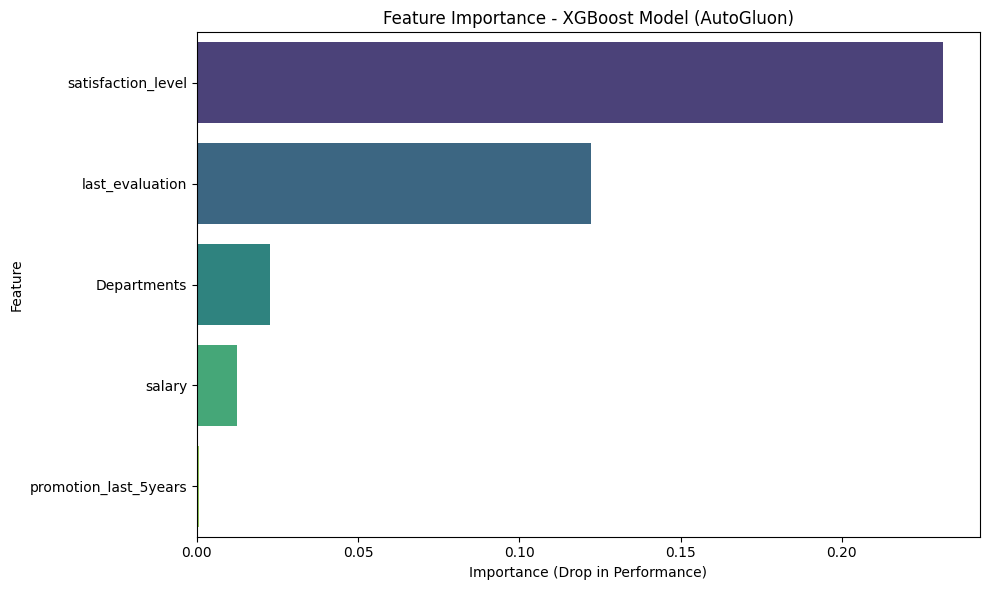

In [24]:
import matplotlib.pyplot as plt
import seaborn as sns

# Calculate feature importances for the XGBoost model using AutoGluon
# This method uses a perturbation-based approach on the test/validation data
feature_importance = predictor.feature_importance(train_data, model='XGBoost')

# Convert to a clean DataFrame
feature_table = feature_importance.reset_index().rename(columns={'index': 'feature'})

# Display the feature importance table
display(feature_table)

# Plot the feature importances
plt.figure(figsize=(10, 6))
sns.barplot(x='importance', y='feature', data=feature_table, palette='viridis', hue='feature', legend=False)
plt.title('Feature Importance - XGBoost Model (AutoGluon)')
plt.xlabel('Importance (Drop in Performance)')
plt.ylabel('Feature')
plt.tight_layout()
plt.show()

In [25]:
# Get and display feature importance using the AutoGluon tabular predictor for our XGBoost model
print("=== Feature Importance Table for XGBoost ===")
display(feature_table[['feature', 'importance', 'stddev']])

=== Feature Importance Table for XGBoost ===


,feature,importance,stddev
0,satisfaction_level,0.23132,0.002667
1,last_evaluation,0.12208,0.002759
2,Departments,0.02268,0.003399
3,salary,0.01240,0.001020
4,promotion_last_5years,0.00068,0.000540


In [26]:
# Access the features used directly by the AutoGluon predictor for XGBoost model inference
xgb_features = predictor.features()
print("Features used by the model:", xgb_features)

Features used by the model: ['satisfaction_level', 'last_evaluation', 'promotion_last_5years', 'Departments', 'salary']


In [27]:
# Print the top predictive feature based on the calculated drop in performance
top_feature = feature_table.iloc[0]['feature']
importance_score = feature_table.iloc[0]['importance']
print(f"The most important feature for our XGBoost model is '{top_feature}' with an importance score of {importance_score:.4f}.")

The most important feature for our XGBoost model is 'satisfaction_level' with an importance score of 0.2313.


In [29]:
feature_table

,feature,importance,stddev,p_value,n,p99_high,p99_low
0,satisfaction_level,0.23132,0.002667,2.119508e-09,5,0.236811,0.225829
1,last_evaluation,0.12208,0.002759,3.128276e-08,5,0.127761,0.116399
2,Departments,0.02268,0.003399,5.875293e-05,5,0.029678,0.015682
3,salary,0.01240,0.001020,5.440699e-06,5,0.014500,0.010300
4,promotion_last_5years,0.00068,0.000540,2.406378e-02,5,0.001793,-0.000433


In [30]:
feature_table.to_gbq('employeedata.feature_table',
                     project_id,
                     chunksize = None,
                     if_exists = 'replace')

/tmp/ipykernel_3754/1242482840.py:1: FutureWarning: Starting with pandas version 3.0 all arguments of to_gbq except for the argument 'destination_table' will be keyword-only.
  feature_table.to_gbq('employeedata.feature_table',
/tmp/ipykernel_3754/1242482840.py:1: FutureWarning: to_gbq is deprecated and will be removed in a future version. Please use pandas_gbq.to_gbq instead: https://pandas-gbq.readthedocs.io/en/latest/api.html#pandas_gbq.to_gbq
  feature_table.to_gbq('employeedata.feature_table',
100%|██████████| 1/1 [00:00<00:00, 10330.80it/s]
